### Objective

The objective of this notebook is to explore customer demographics,
financial behavior, purchasing activity, loyalty, satisfaction, and
channel preferences in the cleaned OmniRetail dataset.

The analysis will identify distributions, relationships, patterns,
and potential variables for customer segmentation and subsequent
dimensionality-reduction and clustering analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("../data/OmniRetail_Cleaned.xlsx")

print("Shape:", df.shape)

Shape: (5200, 22)


### Customer Demographics

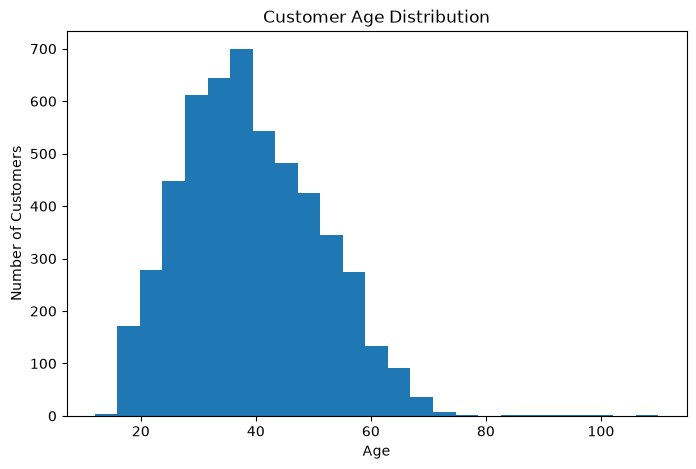

count    5200.000000
mean       39.226154
std        11.922717
min        12.000000
25%        30.000000
50%        38.000000
75%        48.000000
max       110.000000
Name: Age, dtype: float64

In [2]:
plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=25)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

display(df["Age"].describe())

Customer age is concentrated around the younger-to-middle-aged segment, with a gradual decline after approximately age 40 and a relatively small number of very old observations. The concentration around the median may partly reflect median imputation of missing ages.

Region
North      1462
South      1388
West       1245
East       1060
Unknown      45
Name: count, dtype: int64

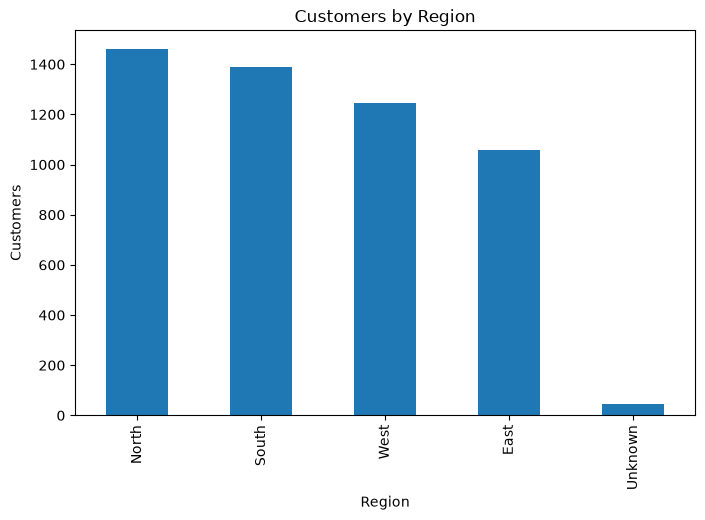

In [3]:
region_counts = (
    df["Region"]
    .value_counts()
)

display(region_counts)

region_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customers by Region")
plt.xlabel("Region")
plt.ylabel("Customers")

plt.show()

Customer distribution is relatively balanced across the four regions, with no single region accounting for a dominant share of the customer base. This suggests that the business has relatively broad geographic coverage rather than being concentrated in one region.

City_Tier
Tier 1    2434
Tier 2    1927
Tier 3     839
Name: count, dtype: int64

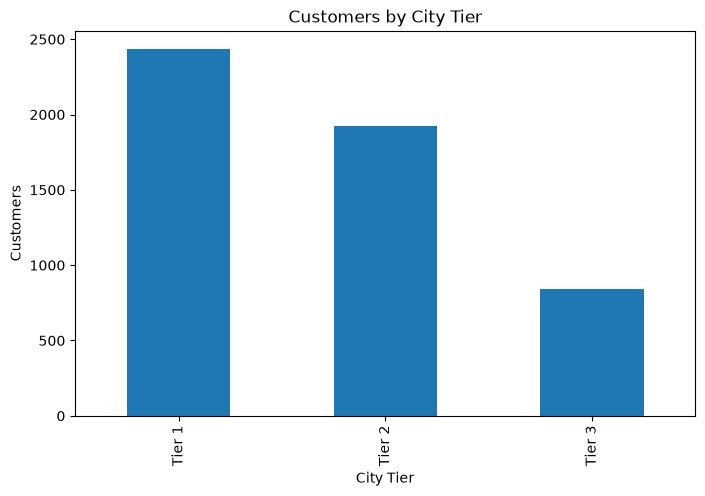

In [4]:
city_counts = df["City_Tier"].value_counts()

display(city_counts)

city_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customers by City Tier")
plt.xlabel("City Tier")
plt.ylabel("Customers")

plt.show()

Customers are concentrated in Tier 1 cities, while Tier 3 cities contribute substantially fewer customers. This suggests that the current customer base is more strongly established in higher-tier urban markets, potentially reflecting the store's existing market reach, purchasing power, or customer acquisition strategy.

### Spending and Financial Behavior

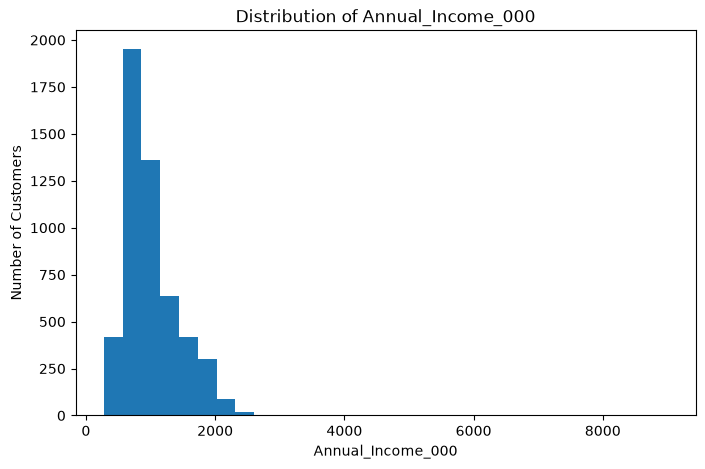

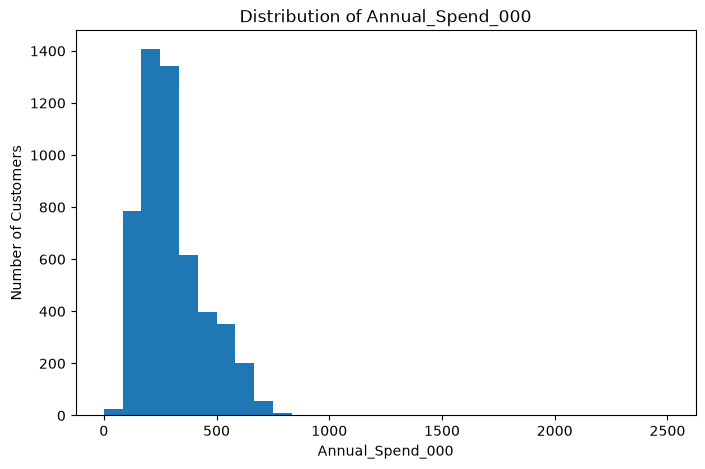

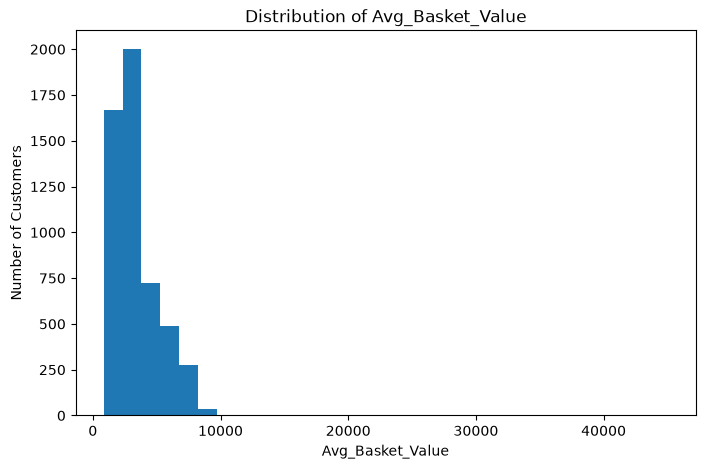

,count,mean,std,min,25%,50%,75%,max
Annual_Income_000,5200.0,1009.274327,467.646157,276.8,693.95,890.0,1207.875,9000.0
Annual_Spend_000,5200.0,302.946846,152.963713,0.0,198.70,267.9,370.150,2500.0
Avg_Basket_Value,5200.0,3408.792462,1905.087064,858.5,2147.80,2878.3,4096.075,45000.0


In [5]:
financial_cols = [
    "Annual_Income_000",
    "Annual_Spend_000",
    "Avg_Basket_Value"
]

for col in financial_cols:

    plt.figure(figsize=(8, 5))

    plt.hist(df[col], bins=30)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Customers")

    plt.show()

display(
    df[financial_cols]
    .describe()
    .T
)

Annual income and annual spending show a strong positive relationship, suggesting that customers with greater financial capacity generally exhibit higher annual spending.

### Purchase and Engagement Behavior

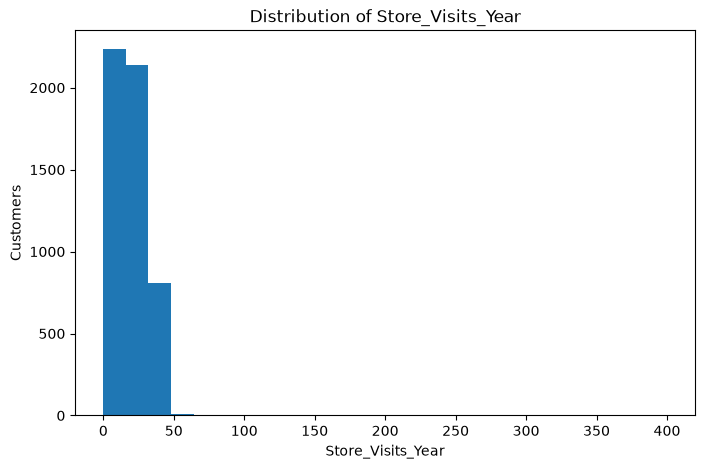

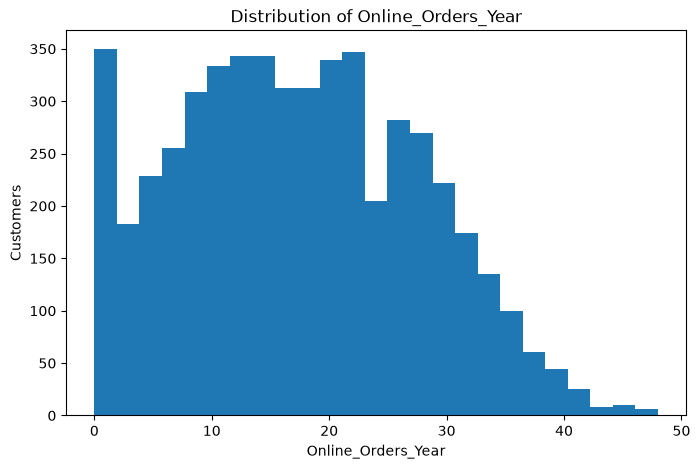

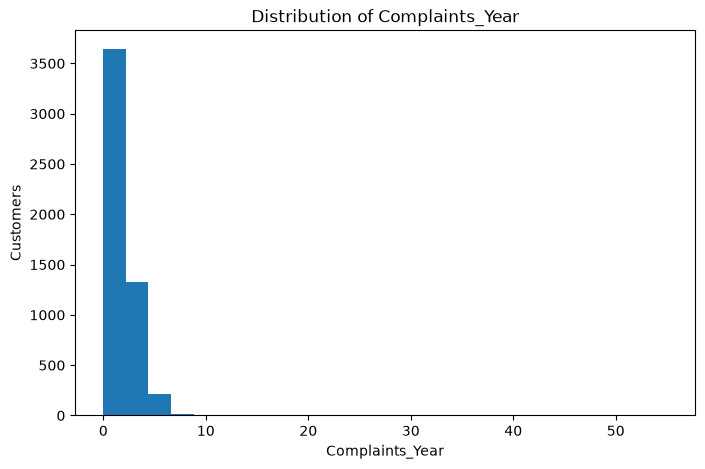

,count,mean,std,min,25%,50%,75%,max
Online_Purchase_Pct,5200.0,47.644462,22.795189,0.0,30.6,47.3,63.900,100.0
Promo_Purchase_Pct,5200.0,37.013712,22.087916,0.0,19.5,34.0,54.425,100.0


In [6]:
activity_cols = [
    "Store_Visits_Year",
    "Online_Orders_Year",
    "Complaints_Year"
]

for col in activity_cols:

    plt.figure(figsize=(8, 5))

    plt.hist(df[col], bins=25)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Customers")

    plt.show()

display(
    df[
        [
            "Online_Purchase_Pct",
            "Promo_Purchase_Pct"
        ]
    ].describe().T
)

Most customers make relatively few store visits annually, while a small group exhibits substantially higher visit frequency. These high-frequency customers may represent an important behavioral segment for later customer segmentation.

Online order frequency is relatively evenly distributed within the observed range, with no major extreme tail comparable to store visits.

Most customers report relatively few complaints per year, while a small number exhibit substantially higher complaint frequency. These customers may represent a potential dissatisfaction or service-risk segment.

In [7]:
income_spend_corr = df[
    ["Annual_Income_000", "Annual_Spend_000"]
].corr().iloc[0, 1]

print("Income-Spend correlation:", round(income_spend_corr, 3))

Income-Spend correlation: 0.617


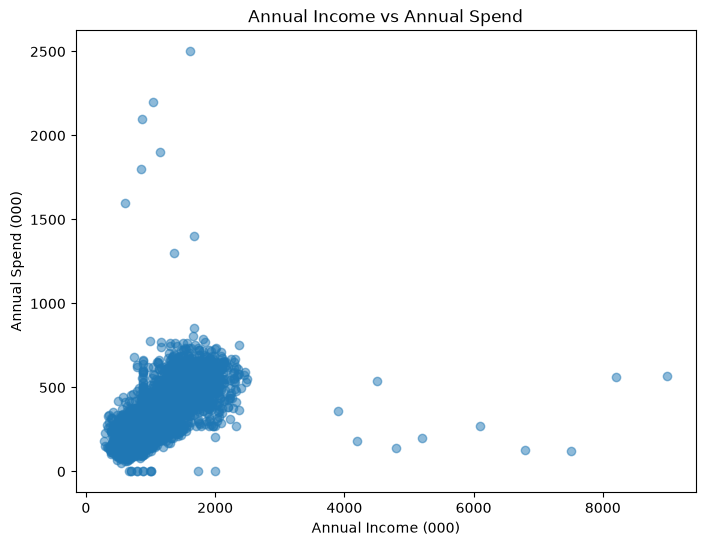

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Annual_Income_000"],
    df["Annual_Spend_000"],
    alpha=0.5
)

plt.title("Annual Income vs Annual Spend")
plt.xlabel("Annual Income (000)")
plt.ylabel("Annual Spend (000)")

plt.show()

### Loyalty and Satisfaction

Membership_Tier
Basic       2153
Silver      1755
Gold         889
Platinum     349
Unknown       54
Name: count, dtype: int64

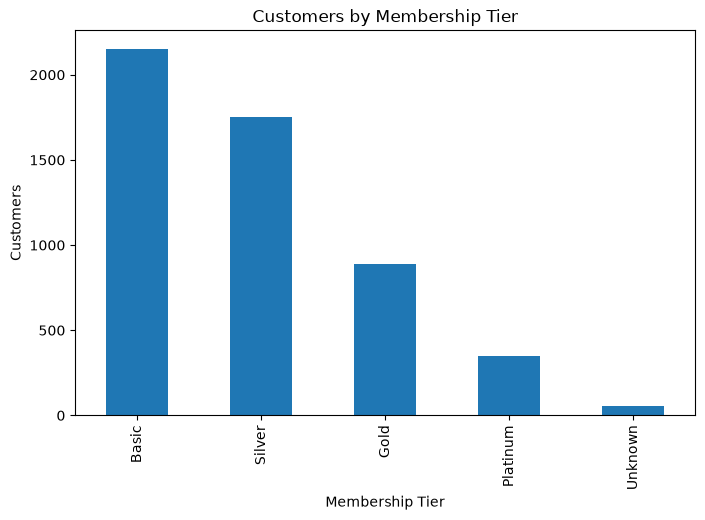

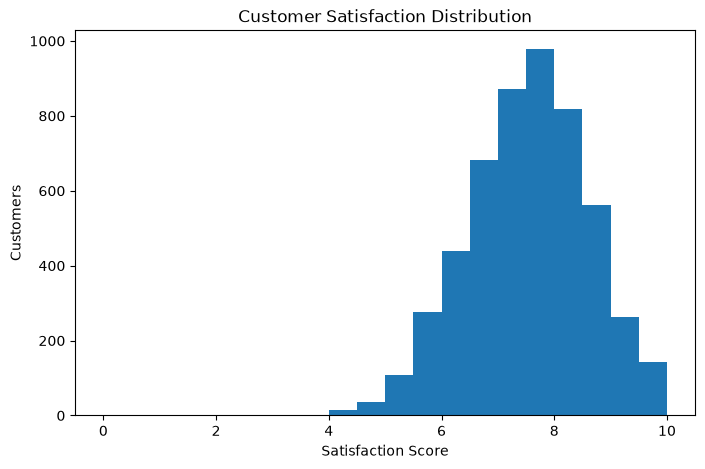

In [9]:
membership_counts = (
    df["Membership_Tier"]
    .value_counts()
)

display(membership_counts)

membership_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customers by Membership Tier")
plt.xlabel("Membership Tier")
plt.ylabel("Customers")

plt.show()

plt.figure(figsize=(8, 5))

plt.hist(
    df["Satisfaction_Score"],
    bins=20
)

plt.title("Customer Satisfaction Distribution")
plt.xlabel("Satisfaction Score")
plt.ylabel("Customers")

plt.show()

Basic membership represents the largest customer group, while Silver and Gold form substantial secondary groups. Although Platinum customers represent a smaller proportion of the base, the segment is large enough to support meaningful comparative analysis.

Customer satisfaction is concentrated toward the higher end of the scale, with relatively fewer customers reporting low satisfaction. This suggests generally favorable customer sentiment, although the lower-satisfaction tail may contain customers requiring attention.

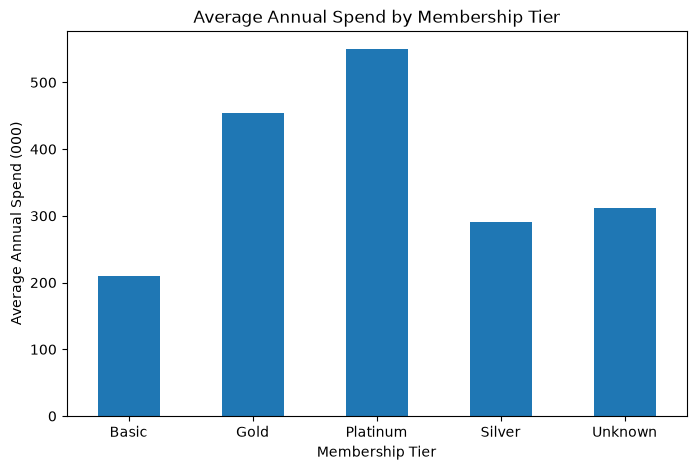

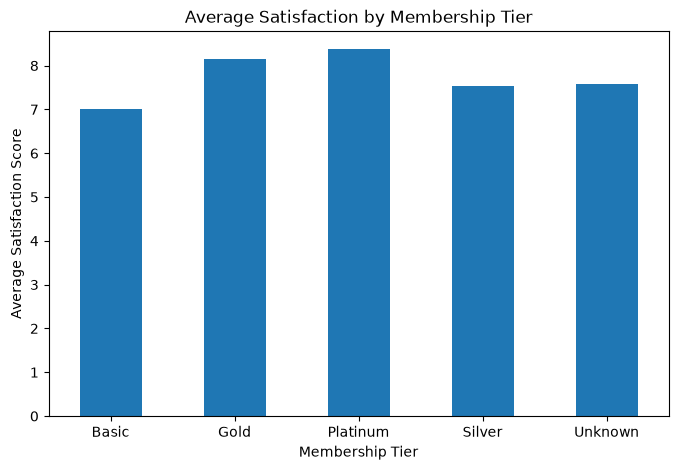

In [10]:
membership_analysis = df.groupby("Membership_Tier")[
    ["Annual_Spend_000", "Satisfaction_Score"]
].mean().round(2)

membership_analysis["Annual_Spend_000"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Annual Spend by Membership Tier")
plt.xlabel("Membership Tier")
plt.ylabel("Average Annual Spend (000)")
plt.xticks(rotation=0)
plt.show()

membership_analysis["Satisfaction_Score"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Satisfaction by Membership Tier")
plt.xlabel("Membership Tier")
plt.ylabel("Average Satisfaction Score")
plt.xticks(rotation=0)
plt.show()

Platinum customers have the highest average annual spending, with spending declining progressively across the lower membership tiers, indicating a meaningful relationship between membership status and customer value. Platinum customers also report the highest satisfaction, although the differences in satisfaction across tiers are relatively small. This suggests that while higher-tier customers are more valuable in terms of spending, overall customer satisfaction remains relatively consistent across membership levels.

### Categorical and Channel Analysis


 Preferred_Category


Preferred_Category
Electronics    913
Beauty         882
Grocery        853
Home           845
Sports         841
Apparel        826
Unknown         40
Name: count, dtype: int64


 Acquisition_Channel


Acquisition_Channel
Organic          1005
Store Walk-in    1004
Search Ads        935
Social Media      905
Referral          713
Marketplace       638
Name: count, dtype: int64

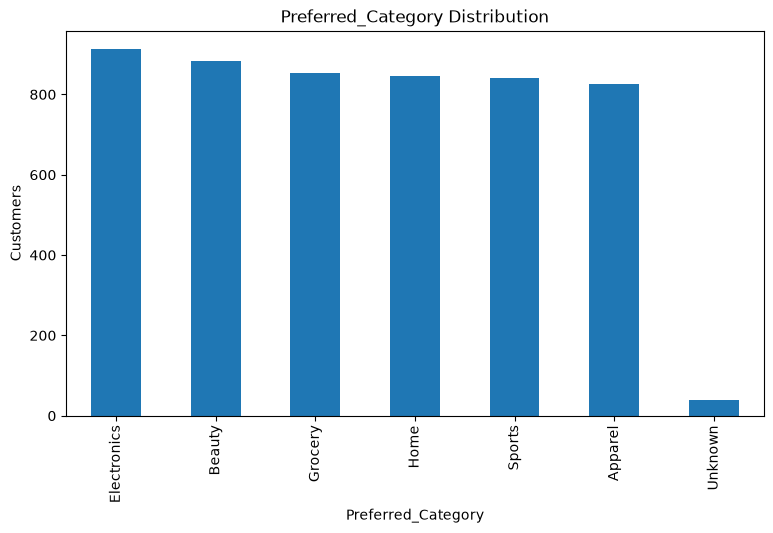

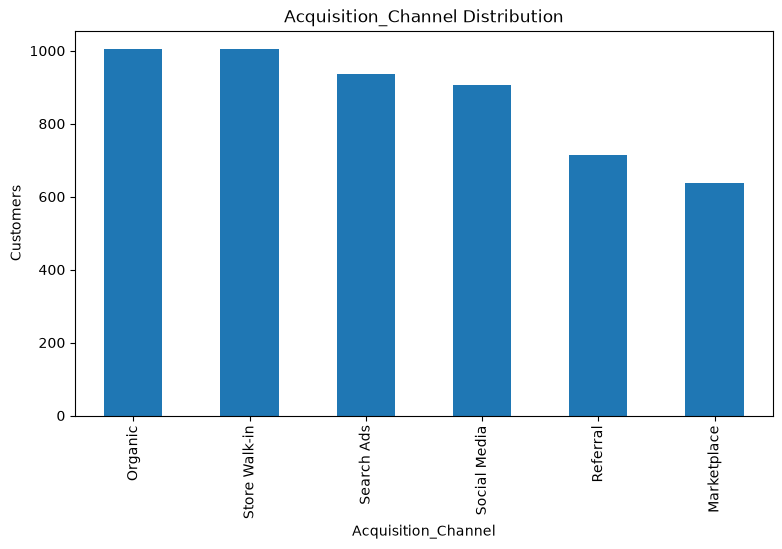

In [11]:
for col in [
    "Preferred_Category",
    "Acquisition_Channel"
]:

    counts = df[col].value_counts()

    print("\n", col)
    display(counts)

for col in [
    "Preferred_Category",
    "Acquisition_Channel"
]:

    df[col].value_counts().plot(
        kind="bar",
        figsize=(9, 5)
    )

    plt.title(f"{col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Customers")

    plt.show()

Customer preferences are relatively evenly distributed across product categories, with no single category accounting for a dominant share. This suggests that the customer base has diverse product interests and that inventory strategy should not rely excessively on a single category.

Referral is one of the smaller acquisition channels relative to Organic, Store Walk-in, Search Ads, and Social Media. This suggests that referral-based acquisition currently contributes less to customer acquisition, although the data alone cannot establish whether this is driven by customer satisfaction or by the referral strategy itself.

           Annual_Income_000  Annual_Spend_000  Online_Orders_Year  \
City_Tier                                                            
Tier 1               1003.29            300.70               17.33   
Tier 2               1002.98            304.45               17.26   
Tier 3               1041.08            306.01               17.45   

           Store_Visits_Year  
City_Tier                     
Tier 1                 18.99  
Tier 2                 19.22  
Tier 3                 19.54  


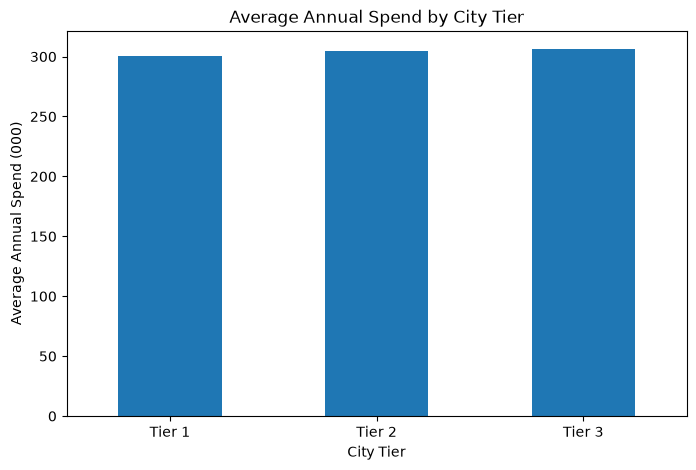

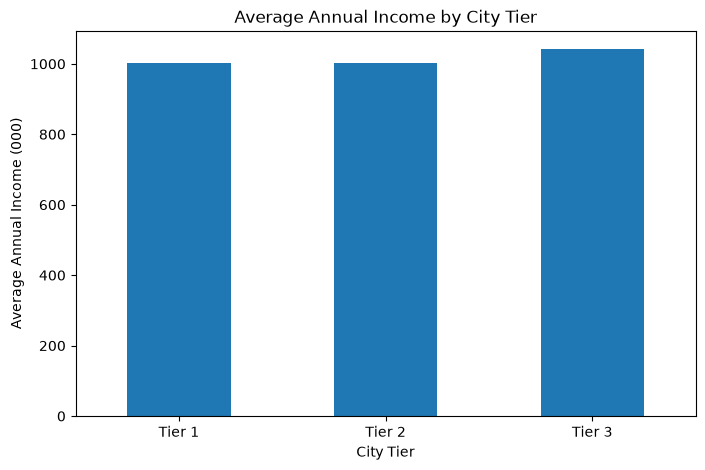

In [12]:
city_tier_analysis = df.groupby("City_Tier")[
    ["Annual_Income_000", "Annual_Spend_000", "Online_Orders_Year", "Store_Visits_Year"]
].mean().round(2)

print(city_tier_analysis)

city_tier_analysis["Annual_Spend_000"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Annual Spend by City Tier")
plt.xlabel("City Tier")
plt.ylabel("Average Annual Spend (000)")
plt.xticks(rotation=0)
plt.show()

city_tier_analysis["Annual_Income_000"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Annual Income by City Tier")
plt.xlabel("City Tier")
plt.ylabel("Average Annual Income (000)")
plt.xticks(rotation=0)
plt.show()

Annual income and annual spending show negligible differences across Tier 1, Tier 2, and Tier 3 cities. This suggests that city tier does not appear to be a major differentiator of customer economic value in the current customer base.

Tier 3 customers have marginally higher online orders and store visits than Tier 2 and Tier 1 customers, respectively. However, the differences are negligible (approximately 0.3), indicating that city tier has little practical influence on customer engagement in the current dataset.

                     Annual_Spend_000  Satisfaction_Score  Online_Orders_Year  \
Acquisition_Channel                                                             
Marketplace                    299.03                7.47               17.54   
Organic                        303.69                7.50               17.29   
Referral                       297.19                7.49               17.12   
Search Ads                     307.94                7.49               17.65   
Social Media                   310.43                7.44               17.69   
Store Walk-in                  297.38                7.49               16.73   

                     Store_Visits_Year  
Acquisition_Channel                     
Marketplace                      19.07  
Organic                          18.95  
Referral                         19.19  
Search Ads                       19.59  
Social Media                     19.49  
Store Walk-in                    18.73  


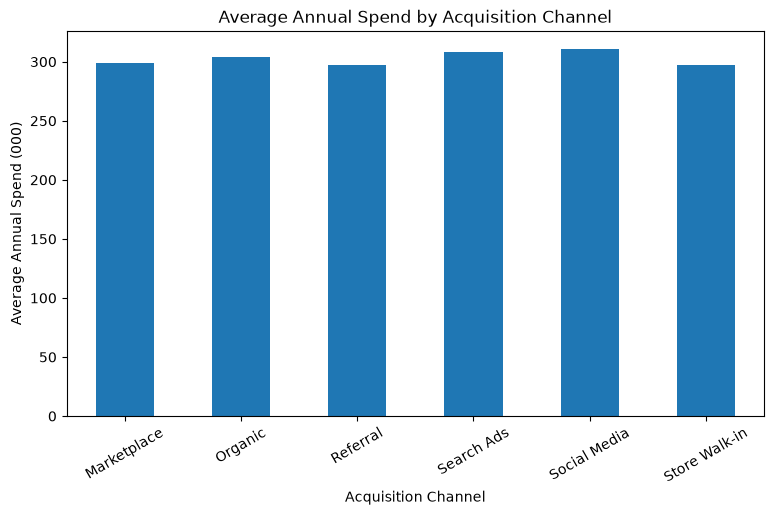

In [13]:
channel_analysis = df.groupby("Acquisition_Channel")[
    [
        "Annual_Spend_000",
        "Satisfaction_Score",
        "Online_Orders_Year",
        "Store_Visits_Year"
    ]
].mean().round(2)

print(channel_analysis)

channel_analysis["Annual_Spend_000"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Annual Spend by Acquisition Channel")
plt.xlabel("Acquisition Channel")
plt.ylabel("Average Annual Spend (000)")
plt.xticks(rotation=30)
plt.show()

Customer behavior remains broadly consistent across acquisition channels. Average annual spending, satisfaction, online orders, and store visits show little variation, with the leading channels exceeding others only by small margins. This suggests that acquisition source does not substantially differentiate customer value or engagement within the current customer base.

### Correlation Analysis

In [14]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

print(numeric_cols)

['Age', 'Annual_Income_000', 'Annual_Spend_000', 'Store_Visits_Year', 'Online_Orders_Year', 'Avg_Basket_Value', 'Online_Purchase_Pct', 'Promo_Purchase_Pct', 'Tenure_Months', 'Return_Rate_Pct', 'Satisfaction_Score', 'Complaints_Year', 'Loyalty_Points']


,Age,Annual_Income_000,Annual_Spend_000,Store_Visits_Year,Online_Orders_Year,Avg_Basket_Value,Online_Purchase_Pct,Promo_Purchase_Pct,Tenure_Months,Return_Rate_Pct,Satisfaction_Score,Complaints_Year,Loyalty_Points
Age,1.00,0.32,0.32,0.49,-0.41,0.31,-0.62,-0.41,0.72,-0.30,0.29,-0.16,0.52
Annual_Income_000,0.32,1.00,0.62,0.34,0.03,0.59,-0.17,-0.57,0.39,-0.35,0.43,-0.25,0.59
Annual_Spend_000,0.32,0.62,1.00,0.35,0.10,0.62,-0.12,-0.61,0.40,-0.39,0.49,-0.27,0.72
Store_Visits_Year,0.49,0.34,0.35,1.00,-0.24,0.32,-0.42,-0.51,0.53,-0.36,0.34,-0.23,0.48
Online_Orders_Year,-0.41,0.03,0.10,-0.24,1.00,0.05,0.62,0.03,-0.40,0.04,0.05,-0.01,-0.11
Avg_Basket_Value,0.31,0.59,0.62,0.32,0.05,1.00,-0.16,-0.55,0.38,-0.35,0.43,-0.24,0.59
Online_Purchase_Pct,-0.62,-0.17,-0.12,-0.42,0.62,-0.16,1.00,0.25,-0.64,0.18,-0.09,0.08,-0.36
Promo_Purchase_Pct,-0.41,-0.57,-0.61,-0.51,0.03,-0.55,0.25,1.00,-0.45,0.52,-0.54,0.35,-0.62
Tenure_Months,0.72,0.39,0.40,0.53,-0.40,0.38,-0.64,-0.45,1.00,-0.33,0.33,-0.18,0.70
Return_Rate_Pct,-0.30,-0.35,-0.39,-0.36,0.04,-0.35,0.18,0.52,-0.33,1.00,-0.38,0.23,-0.40


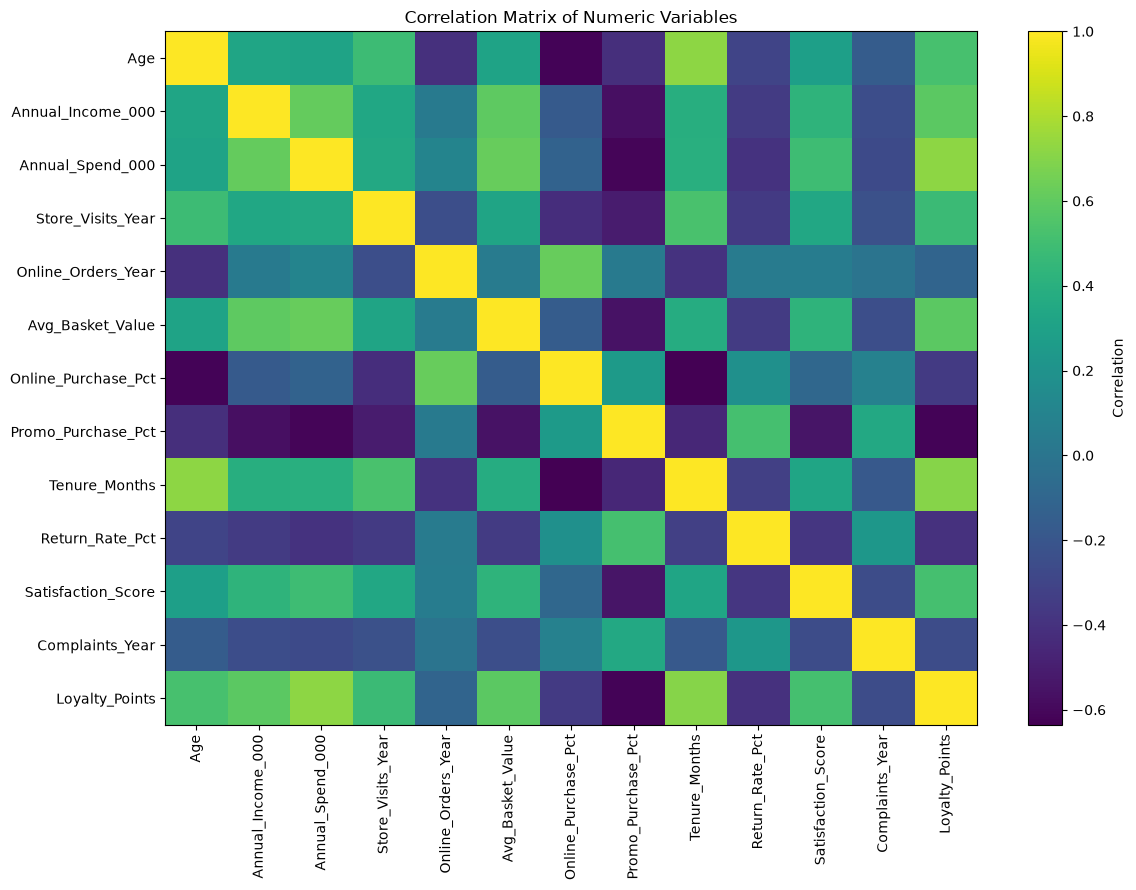

In [15]:
correlation_matrix = (
    df[numeric_cols]
    .corr()
)

display(
    correlation_matrix.round(2)
)

plt.figure(figsize=(12, 9))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.xticks(
    range(len(numeric_cols)),
    numeric_cols,
    rotation=90
)

plt.yticks(
    range(len(numeric_cols)),
    numeric_cols
)

plt.colorbar(
    label="Correlation"
)

plt.title("Correlation Matrix of Numeric Variables")

plt.tight_layout()
plt.show()

## Key EDA Findings

The exploratory analysis revealed several important patterns in the customer base:

1. **Customer age:** The majority of customers fall between approximately 20 and 60 years of age, with the distribution concentrated around the mid-30s.

2. **Income and spending:** Annual income and annual spending show broadly similar distribution patterns and a moderate positive correlation (r = 0.62), indicating that higher-income customers generally tend to spend more.

3. **City tier:** Tier 1 cities have the highest concentration of customers; however, customers from Tier 1 cities do not have meaningfully higher income or spending than customers from Tier 2 or Tier 3 cities.

4. **Customer satisfaction:** Satisfaction levels remain relatively high and consistent across membership tiers and city tiers, suggesting that the company is able to maintain a broadly positive customer experience across different customer groups.

5. **Membership value:** Platinum members have substantially higher annual spending than customers in the lower membership tiers. However, the difference in satisfaction across membership tiers is relatively small.

6. **Customer complaints:** Most customers register relatively few complaints per year, indicating generally low levels of reported service dissatisfaction within the customer base.

7. **Acquisition channel:** Customer spending, satisfaction, online orders, and store visits show little variation across acquisition channels, suggesting that acquisition source does not strongly differentiate customer value or engagement.

8. **Promotional behavior:** Higher promotional purchase dependence is negatively associated with both annual spending and satisfaction, indicating that promotion-heavy customers may represent a distinct segment requiring further investigation.

9. **Digital behavior and age:** Age is negatively associated with online purchase percentage, suggesting that younger customers tend to have a greater proportion of online purchases.

10. **Loyalty:** Annual spending is positively associated with loyalty points, indicating that higher-value customers generally accumulate more loyalty rewards.